In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
data=pd.read_excel(r"D:\Abhinav\Python-FullStack-DS-AI-200-Days\Day39\dataset\Online Retail.xlsx")

In [4]:
df=pd.DataFrame(data)

In [5]:
print(df.shape)
print(df.columns)
print(df.dtypes)

(541909, 8)
Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country'],
      dtype='str')
InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[us]
UnitPrice             float64
CustomerID            float64
Country                   str
dtype: object


In [6]:
print(df.isnull().sum())
print(df.duplicated().sum())
print(df.describe())

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64
5268
            Quantity                 InvoiceDate      UnitPrice     CustomerID
count  541909.000000                      541909  541909.000000  406829.000000
mean        9.552250  2011-07-04 13:34:57.156386       4.611114   15287.690570
min    -80995.000000         2010-12-01 08:26:00  -11062.060000   12346.000000
25%         1.000000         2011-03-28 11:34:00       1.250000   13953.000000
50%         3.000000         2011-07-19 17:17:00       2.080000   15152.000000
75%        10.000000         2011-10-19 11:27:00       4.130000   16791.000000
max     80995.000000         2011-12-09 12:50:00   38970.000000   18287.000000
std       218.081158                         NaN      96.759853    1713.600303


In [7]:
df.columns.str.strip()
df.head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
5,536365,22752,SET 7 BABUSHKA NESTING BOXES,2,2010-12-01 08:26:00,7.65,17850.0,United Kingdom
6,536365,21730,GLASS STAR FROSTED T-LIGHT HOLDER,6,2010-12-01 08:26:00,4.25,17850.0,United Kingdom
7,536366,22633,HAND WARMER UNION JACK,6,2010-12-01 08:28:00,1.85,17850.0,United Kingdom
8,536366,22632,HAND WARMER RED POLKA DOT,6,2010-12-01 08:28:00,1.85,17850.0,United Kingdom
9,536367,84879,ASSORTED COLOUR BIRD ORNAMENT,32,2010-12-01 08:34:00,1.69,13047.0,United Kingdom


In [8]:
corr=df[["CustomerID","UnitPrice"]].corr()
print(corr)

            CustomerID  UnitPrice
CustomerID     1.00000   -0.00456
UnitPrice     -0.00456    1.00000


In [9]:
df["Description"]=df["Description"].fillna("No Description")

In [10]:
customer_df=df[df["CustomerID"].notna()].copy()
print("Customer Id Rows for analysis:",len(customer_df))
print("Customer ID with no rows for analysis:",customer_df["CustomerID"].isnull().sum())

Customer Id Rows for analysis: 406829
Customer ID with no rows for analysis: 0


In [11]:
df_clean = df.drop_duplicates().copy()

print("Rows before cleaning:", len(df))
print("Rows after cleaning:", len(df_clean))
print("Duplicates remaining:", df_clean.duplicated().sum())

Rows before cleaning: 541909
Rows after cleaning: 536641
Duplicates remaining: 0


In [12]:
df["SalesValue"]=df["Quantity"]*df["UnitPrice"]

In [13]:
# Clean invoice numbers before checking
invoice_numbers = df_clean["InvoiceNo"].astype(str).str.strip()

# Identify cancellation invoices
cancellations = invoice_numbers.str.startswith("C", na=False)

# Store cancellation records
cancel_df = df_clean[cancellations].copy()

# Display results
print("Total cancellation records:", len(cancel_df))
print(cancel_df.head(10))
print("Total cancellation records:",len(cancel_df))
print(cancel_df.head(10))

Total cancellation records: 9251
    InvoiceNo StockCode                        Description  Quantity  \
141   C536379         D                           Discount        -1   
154   C536383    35004C    SET OF 3 COLOURED  FLYING DUCKS        -1   
235   C536391     22556     PLASTERS IN TIN CIRCUS PARADE        -12   
236   C536391     21984   PACK OF 12 PINK PAISLEY TISSUES        -24   
237   C536391     21983   PACK OF 12 BLUE PAISLEY TISSUES        -24   
238   C536391     21980  PACK OF 12 RED RETROSPOT TISSUES        -24   
239   C536391     21484        CHICK GREY HOT WATER BOTTLE       -12   
240   C536391     22557   PLASTERS IN TIN VINTAGE PAISLEY        -12   
241   C536391     22553             PLASTERS IN TIN SKULLS       -24   
939   C536506     22960           JAM MAKING SET WITH JARS        -6   

            InvoiceDate  UnitPrice  CustomerID         Country  
141 2010-12-01 09:41:00      27.50     14527.0  United Kingdom  
154 2010-12-01 09:49:00       4.65     15311

In [14]:
print("Sample invoice numbers:")
print(df_clean["InvoiceNo"].head(20).tolist())
print("Invoice numbers containing C:")
print(
    df_clean[
        df_clean["InvoiceNo"].astype(str).str.contains("C", case=False, na=False)
    ]["InvoiceNo"].head(20).tolist()
)
print("Invoice numbers starting with C after stripping spaces:")
print(
    df_clean[
        df_clean["InvoiceNo"].astype(str).str.strip().str.startswith("C")
    ]["InvoiceNo"].head(20).tolist()
)

print("Invoice number data type:")
print(df_clean["InvoiceNo"].dtype)

Sample invoice numbers:
[536365, 536365, 536365, 536365, 536365, 536365, 536365, 536366, 536366, 536367, 536367, 536367, 536367, 536367, 536367, 536367, 536367, 536367, 536367, 536367]
Invoice numbers containing C:
['C536379', 'C536383', 'C536391', 'C536391', 'C536391', 'C536391', 'C536391', 'C536391', 'C536391', 'C536506', 'C536543', 'C536543', 'C536548', 'C536548', 'C536548', 'C536548', 'C536548', 'C536548', 'C536548', 'C536548']
Invoice numbers starting with C after stripping spaces:
['C536379', 'C536383', 'C536391', 'C536391', 'C536391', 'C536391', 'C536391', 'C536391', 'C536391', 'C536506', 'C536543', 'C536543', 'C536548', 'C536548', 'C536548', 'C536548', 'C536548', 'C536548', 'C536548', 'C536548']
Invoice number data type:
object


In [15]:
print("Negative quantities in cancellations:",
      (cancel_df["Quantity"] < 0).sum())

print("Positive quantities in cancellations:",
      (cancel_df["Quantity"] > 0).sum())

Negative quantities in cancellations: 9251
Positive quantities in cancellations: 0


In [16]:
# Calculate sales value for every transaction
df_clean["SalesValue"] = df_clean["Quantity"] * df_clean["UnitPrice"]

# Calculate cancellation value
cancel_df = cancel_df.copy()
cancel_df["SalesValue"] = cancel_df["Quantity"] * cancel_df["UnitPrice"]

print("Total cancellation value:", cancel_df["SalesValue"].sum())

print("Sales including cancellations:", df_clean["SalesValue"].sum())

print("Sales excluding cancellations:",
      df_clean.loc[~cancellations, "SalesValue"].sum())

Total cancellation value: -893979.73
Sales including cancellations: 9726006.954
Sales excluding cancellations: 10619986.684


In [17]:
df_clean["Month"] = df_clean["InvoiceDate"].dt.to_period("M")

In [18]:
monthly_sales = (
    df_clean.loc[~cancellations]
    .groupby("Month")["SalesValue"]
    .sum()
    .sort_index()
)

print("Monthly sales:")
print(monthly_sales)

Monthly sales:
Month
2010-12     821452.730
2011-01     689811.610
2011-02     522545.560
2011-03     716215.260
2011-04     536968.491
2011-05     769296.610
2011-06     760547.010
2011-07     718076.121
2011-08     735717.260
2011-09    1056435.192
2011-10    1151263.730
2011-11    1503866.780
2011-12     637790.330
Freq: M, Name: SalesValue, dtype: float64


In [19]:
print("Month with highest sales:", monthly_sales.idxmax())
print("Highest monthly sales value:", monthly_sales.max())

Month with highest sales: 2011-11
Highest monthly sales value: 1503866.78


In [20]:
monthly_sales.to_csv("monthly_sales.csv")

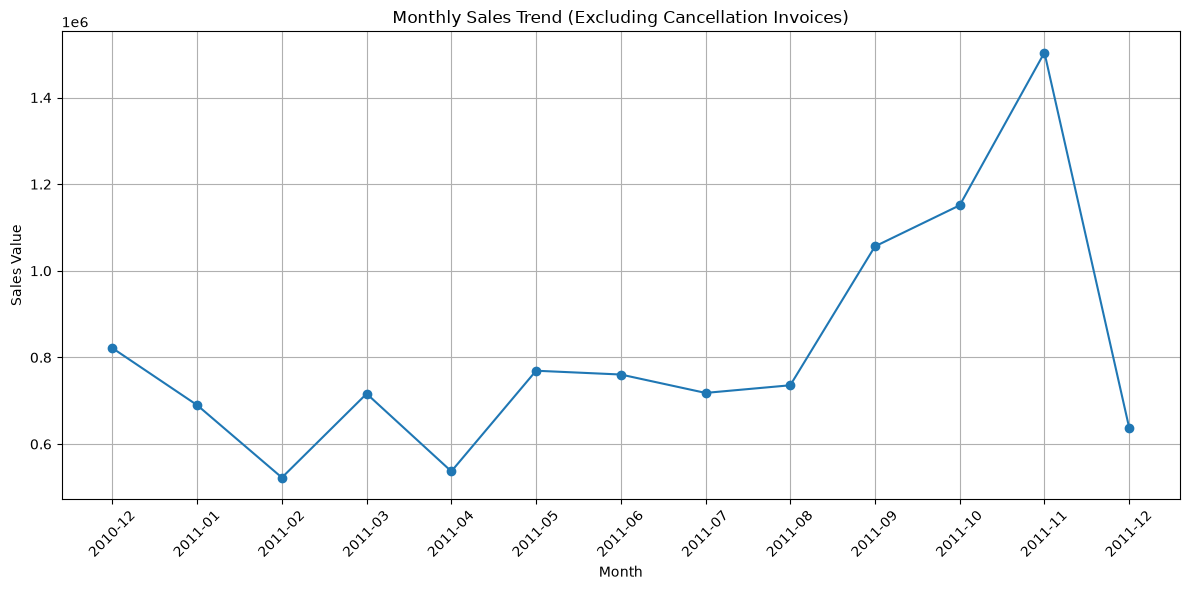

Monthly sales chart saved to output/monthly_sales.png


In [21]:
import os
import matplotlib.pyplot as plt

# Create output folder if it doesn't exist
os.makedirs("output", exist_ok=True)

# Plot monthly sales
plt.figure(figsize=(12, 6))
plt.plot(
    monthly_sales.index.astype(str),
    monthly_sales.values,
    marker="o"
)

plt.title("Monthly Sales Trend (Excluding Cancellation Invoices)")
plt.xlabel("Month")
plt.ylabel("Sales Value")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()

# Save the chart
plt.savefig("output/monthly_sales.png", dpi=300)
plt.show()

print("Monthly sales chart saved to output/monthly_sales.png")